# [Bonus Tasks](svm_segm.ipynb)

In [70]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [61]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [62]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [77]:
def create_data_matrix (img):
    patches = skimage.util.view_as_blocks (img, patch_sizes)
    X = patches.reshape (-1, patch_sizes[0]*patch_sizes [1])
    return X

**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [84]:
def create_gt_labels_vector (gt):
    patches = skimage.util.view_as_blocks (gt,patch_sizes)
    labels = []
    for patch in patches.reshape (-1, patch_sizes [0], patch_sizes[1]):
        foreground = patch.mean ()

        if foreground > 0.5:
            labels.append (1)
        elif foreground ==0:
            labels.append (-1)
        else: 
            labels.append (0)
    return np.array (labels) 

**[Task 1.3.]()** Create the SVM classifier:

In [79]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

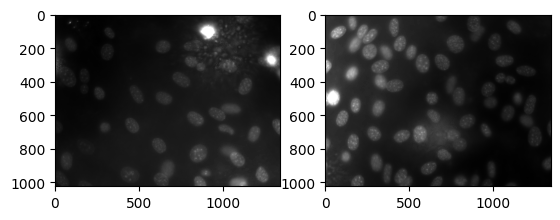

In [ ]:
img33 = plt.imread ('data/NIH3T3/im/dna-33.png')
img44 = plt.imread ('data/NIH3T3/im/dna-44.png')

X33 = create_data_matrix (img33)
X44 = create_data_matrix (img44)

plt.figure()
plt.subplot (1,2,1)
plt.imshow (img33, 'gray')
plt.subplot (1,2,2)
plt.imshow (img44, 'gray')

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [85]:
gt33 = plt.imread ('data/NIH3T3/im/dna-33.png')
gt44 = plt.imread ('data/NIH3T3/im/dna-44.png')

Y33 = create_gt_labels_vector (gt33)
Y44 = create_gt_labels_vector (gt44)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

**[Task 1.4.]()** Implement the function `predict_image`:

Test your implementation:

In [ ]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.imshow(blend_result(img, seg))

**[Task 1.5.]()** Perform batch processing: